Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Shape: (442, 10)

Bias (intercept): 151.35
Weights:
   age:    37.90
   sex:  -241.96
   bmi:   542.43
    bp:   347.70
    s1:  -931.49
    s2:   518.06
    s3:   163.42
    s4:   275.32
    s5:   736.20
    s6:    48.67

Test MSE: 2900.19
Test RMSE: 53.85  (average error in the label's units)


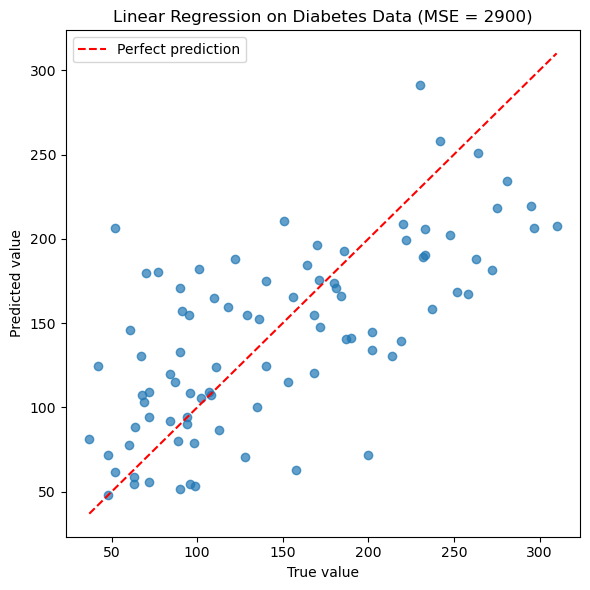

In [1]:
"""
Week 1 - Linear Regression on the sklearn diabetes dataset.
Fits a model, plots predictions vs. truth, and computes MSE.
"""
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# 1. Load data
#    X = features (age, bmi, blood pressure, ...), y = label (disease progression after 1 year)
X, y = load_diabetes(return_X_y=True, as_frame=True)
print("Features:", list(X.columns))
print("Shape:", X.shape)

# 2. Split: train on 80%, test on the 20% the model has never seen
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Train the model (it learns the bias b and weights w)
model = LinearRegression()
model.fit(X_train, y_train)

print("\nBias (intercept):", round(model.intercept_, 2))
print("Weights:")
for name, w in zip(X.columns, model.coef_):
    print(f"  {name:>4}: {w:8.2f}")

# 4. Predict on the test set
y_pred = model.predict(X_test)

# 5. Loss: Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print(f"\nTest MSE: {mse:.2f}")
print(f"Test RMSE: {mse ** 0.5:.2f}  (average error in the label's units)")

# 6. Plot predictions vs. truth
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("True value")
plt.ylabel("Predicted value")
plt.title(f"Linear Regression on Diabetes Data (MSE = {mse:.0f})")
plt.legend()
plt.tight_layout()
plt.savefig("predictions_vs_truth.png", dpi=150)
plt.show()